# Пример расчета прямого и обратного прохода при обучении сети.

<img src='images/ris0_1.png' width=600, heigth=440> <br>
<img src='images/ris0_2.png' width=600, heigth=440> <br>
<img src='images/ris0_3.png' width=600, heigth=440> <br>
<img src='images/ris1_1.png' width=600, heigth=440> <br>
<img src='images/ris1_2.png' width=600, heigth=440> <br>


# Открытие датасета

# Импорты
Нужно установить PyTorch 

In [32]:
import math
import csv
import numpy as np

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import gridspec



#---------
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision
from torchvision import transforms
from torchvision.transforms.functional import normalize
import torchvision.datasets as dset

from torch.utils.data import Dataset, DataLoader
from torch.utils.data.sampler import SubsetRandomSampler, Sampler
from tqdm import tqdm
from sklearn.metrics import classification_report

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [33]:
#Возьмем данные из модуля datasets библиотеки Scikit-learn. Вначале загрузим их.
from sklearn import datasets
raw_data = datasets.load_wine()

In [34]:
# посмотрим на составляющие датасета
raw_data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])

In [35]:
# определим тип данных нашего датасета
type(raw_data)

sklearn.utils._bunch.Bunch

In [36]:
# разбиение датасета на с цифрами на тестовый и обучающий
MNIST_train = torchvision.datasets.MNIST(root='./data', 
                                           train=True, 
                                           transform=transforms.ToTensor(),  
                                           download=True)
MNIST_test = torchvision.datasets.MNIST(root='./data', 
                                          train=False, 
                                          transform=transforms.ToTensor())


C:\Users\valentin\AppData\Local\Temp\ipykernel_5076\357252736.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  ax[i].imshow(np.array(MNIST_train[i][0][0]), 'gray')


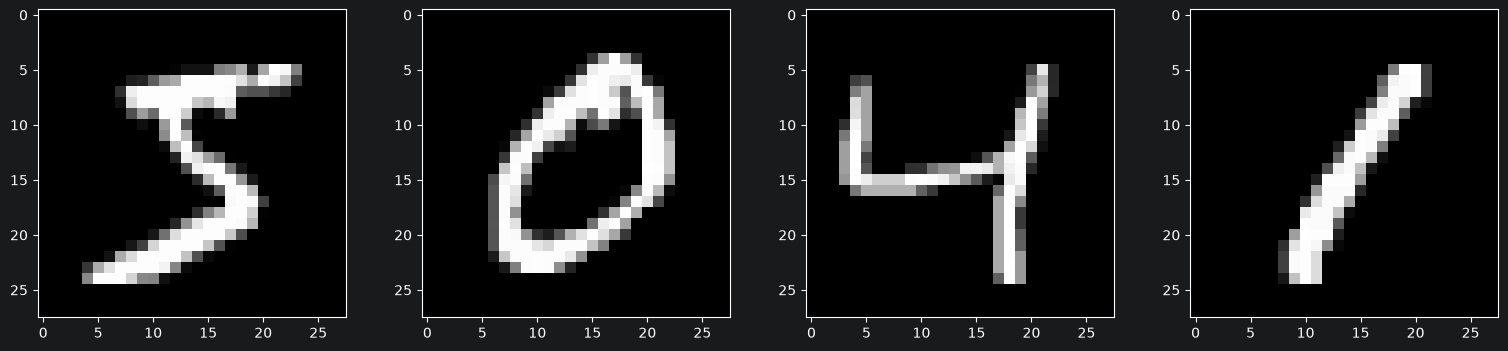

In [37]:
# отображение датасета с  цифрами
fig, gs = plt.figure(figsize=(19,4)), gridspec.GridSpec(1, 4) 
ax = []
for i in range(4):
    ax.append(fig.add_subplot(gs[i]))
    ax[i].imshow(np.array(MNIST_train[i][0][0]), 'gray')
plt.show()

In [38]:
# создание класса perceptron
class Perceptron(torch.nn.Module):
    def __init__(self, input_dim=784, num_layers=0,
            hidden_dim=64, output_dim=10, p=0.0, device='cpu'): 
        super(Perceptron, self).__init__()
        self.layers = torch.nn.Sequential()
        prev_size = input_dim 
        for i in range(num_layers):
            self.layers.add_module('layer{}'.format(i), torch.nn.Linear(prev_size, hidden_dim)) 
            self.layers.add_module('relu{}'.format(i), torch.nn.ReLU())
            self.layers.add_module('dropout{}'.format(i), torch.nn.Dropout(p=p)) 
            prev_size = hidden_dim
        self.layers.add_module('classifier',
            torch.nn.Linear(prev_size, output_dim))
        self.to(device)

    def forward(self, input):
        return self.layers(input)


In [39]:
# это объект, обозначающий устройство, на котором размещен или будет размещен torch.Tensor \
# Torch.device содержит тип устройства («процессор» или « cuda»)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") 
device


device(type='cpu')

In [40]:
# Создание модели без внутренних слоев 
model = Perceptron(device=device) 
model

Perceptron(
  (layers): Sequential(
    (classifier): Linear(in_features=784, out_features=10, bias=True)
  )
)

In [41]:

model = Perceptron(num_layers=5, device=device) 
model

Perceptron(
  (layers): Sequential(
    (layer0): Linear(in_features=784, out_features=64, bias=True)
    (relu0): ReLU()
    (dropout0): Dropout(p=0.0, inplace=False)
    (layer1): Linear(in_features=64, out_features=64, bias=True)
    (relu1): ReLU()
    (dropout1): Dropout(p=0.0, inplace=False)
    (layer2): Linear(in_features=64, out_features=64, bias=True)
    (relu2): ReLU()
    (dropout2): Dropout(p=0.0, inplace=False)
    (layer3): Linear(in_features=64, out_features=64, bias=True)
    (relu3): ReLU()
    (dropout3): Dropout(p=0.0, inplace=False)
    (layer4): Linear(in_features=64, out_features=64, bias=True)
    (relu4): ReLU()
    (dropout4): Dropout(p=0.0, inplace=False)
    (classifier): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [42]:
# процедура терстирования модели 
def testing(model, dataset):
    generator = torch.utils.data.DataLoader(dataset, batch_size=64)
    pred = []
    real = []
    for x, y in tqdm(generator, leave=False):
        x = x.view([-1, 784]).to(device) 
        y = y.to(device)
        pred.extend(torch.argmax(model(x), dim=-1).cpu().numpy().tolist()) 
        real.extend(y.cpu().numpy().tolist())
    
    return np.mean(np.array(real) == np.array(pred)), classification_report(real, pred)


In [43]:
# процедура тренировки модели
def trainer(model, dataset, loss_function, optimizer, epochs): 
    for epoch in tqdm(range(epochs), leave=False):
        generator = torch.utils.data.DataLoader(dataset, batch_size=64,
            shuffle=True)

        for x, y in tqdm(generator, leave=False):
            optimizer.zero_grad() 
            x = x.view([-1, 784]).to(device) 
            y = y.to(device)
            output = model(x)
            loss = loss_function(output, y)
            loss.backward()
            optimizer.step()


In [44]:
model = Perceptron(num_layers=0, device=device)


In [45]:
# Результат, получаемый от необученной модели.
_ = model.eval()
acc, report = testing(model, MNIST_test) 
print(report)

              precision    recall  f1-score   support

           0       0.01      0.01      0.01       980
           1       0.03      0.05      0.03      1135
           2       0.02      0.00      0.00      1032
           3       0.04      0.00      0.00      1010
           4       0.01      0.01      0.01       982
           5       0.36      0.03      0.05       892
           6       0.05      0.01      0.01       958
           7       0.02      0.01      0.02      1028
           8       0.05      0.11      0.07       974
           9       0.08      0.28      0.13      1009

    accuracy                           0.05     10000
   macro avg       0.07      0.05      0.03     10000
weighted avg       0.06      0.05      0.03     10000



In [46]:
# Обучение модели
_ = model.train()
trainer(model=model,
    dataset=MNIST_train,
    loss_function=torch.nn.CrossEntropyLoss(),
    optimizer=torch.optim.Adam(model.parameters(), lr=0.001), 
    epochs=4)


100%|█████████▉| 935/938 [00:16<00:00, 56.80it/s]


In [47]:
# Результат обучения классификатора
_ = model.eval()
acc, report = testing(model, MNIST_test) 
print(report)

              precision    recall  f1-score   support

           0       0.95      0.98      0.96       980
           1       0.97      0.98      0.97      1135
           2       0.94      0.88      0.91      1032
           3       0.90      0.92      0.91      1010
           4       0.93      0.94      0.93       982
           5       0.91      0.85      0.88       892
           6       0.93      0.96      0.94       958
           7       0.93      0.93      0.93      1028
           8       0.88      0.88      0.88       974
           9       0.90      0.90      0.90      1009

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



Задание: С помощью нейронной сети классифицировать вина по качеству. Датасет взять из третьей работы. Разбить датасет на два класса по качеству вина. Качество вина до пяти включительно определить как первый класс, свыше пяти - как второй.
Представить основные показатели метода. Сравнить результат классификации с результатом из третьей работы.

In [48]:
df = pd.read_csv("data/wine/wine.csv")

### EDA

In [49]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [50]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [52]:
num_cols = df.columns[:-1]
target = df.columns[-1]

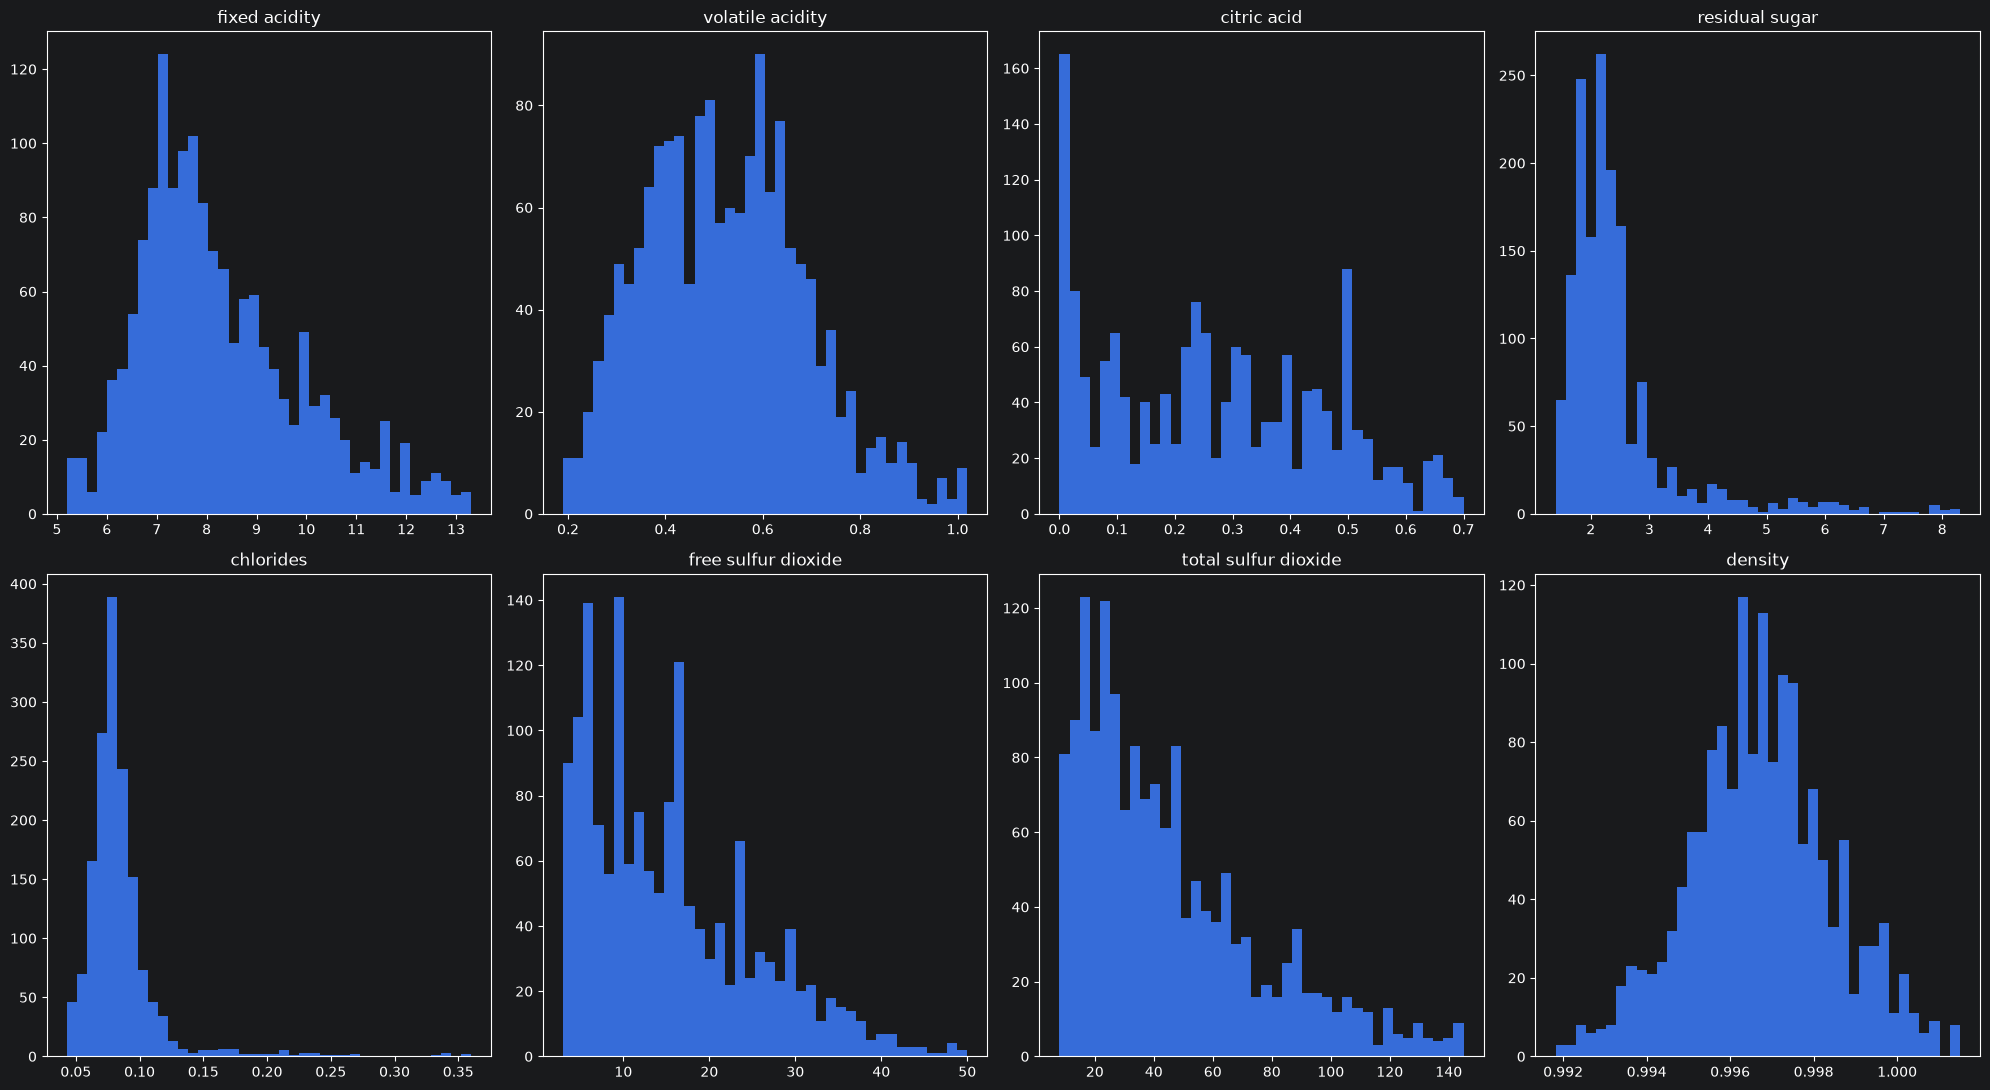

In [53]:
fig, axes = plt.subplots(2, 4, figsize=(20, 11))
for ax, c in zip(axes.ravel(), num_cols):
  s = df[c].dropna()
  ax.hist(s[(s >= s.quantile(0.01)) & (s <= s.quantile(0.99))], bins=40)
  ax.set_title(c)
plt.tight_layout()
plt.show()

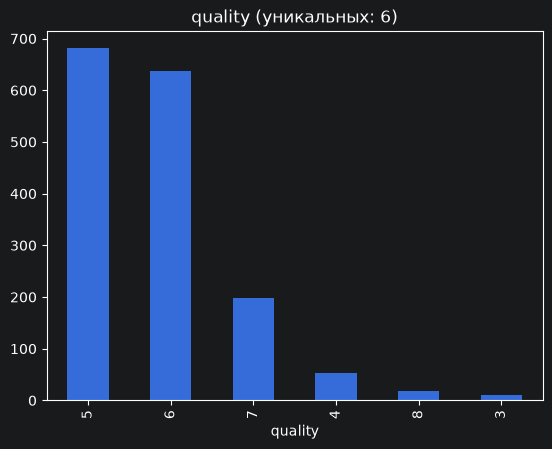

In [54]:

df[target].value_counts().head(15).plot(kind='bar')
plt.title(target + ' (уникальных: ' + str(df[target].nunique()) + ')')
plt.show()


### Препроцессинг

In [55]:
from sklearn.model_selection import train_test_split

print('Пропусков:', df.isna().sum().sum())
print('Дубликатов:', df.duplicated().sum())

df = df.drop_duplicates().dropna().reset_index(drop=True)

df[target] = (df[target] > 5).astype(int)

X = df.drop(columns=[target])
y = df[target]

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.25, stratify=y_train, random_state=42)

print(x_train.shape, x_val.shape, x_test.shape)
print('Доля класса 1 в train:', y_train.mean(), '| в val:', y_val.mean(), '| в test:', y_test.mean())

Пропусков: 0
Дубликатов: 240
(815, 11) (272, 11) (272, 11)
Доля класса 1 в train: 0.5288343558282208 | в val: 0.5294117647058824 | в test: 0.5294117647058824


In [56]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_val)
x_test_scaled = scaler.transform(x_test)

In [57]:
train_dataset = torch.utils.data.TensorDataset(
    torch.tensor(x_train_scaled, dtype=torch.float32),
    torch.tensor(y_train.values, dtype=torch.long))
val_dataset = torch.utils.data.TensorDataset(
    torch.tensor(x_val_scaled, dtype=torch.float32),
    torch.tensor(y_val.values, dtype=torch.long))
test_dataset = torch.utils.data.TensorDataset(
    torch.tensor(x_test_scaled, dtype=torch.float32),
    torch.tensor(y_test.values, dtype=torch.long))

input_dim = x_train_scaled.shape[1]

print('Размеры датасетов:', len(train_dataset), len(val_dataset), len(test_dataset))

Размеры датасетов: 815 272 272


### Модель
Используем класс `Perceptron` сразу с двумя скрытыми слоями и dropout. Входов 11 (признаки вина), выходов 2 (классы). Для обучения выделена валидационная выборка: по ней `ReduceLROnPlateau` снижает learning rate, когда val loss перестаёт улучшаться, а early stopping останавливает обучение и возвращает веса с наилучшим val loss.

In [58]:
def testing_wine(model, dataset):
    generator = torch.utils.data.DataLoader(dataset, batch_size=64)
    pred = []
    real = []
    with torch.no_grad():
        for x, y in generator:
            x = x.to(device)
            y = y.to(device)
            pred.extend(torch.argmax(model(x), dim=-1).cpu().numpy().tolist())
            real.extend(y.cpu().numpy().tolist())

    return np.mean(np.array(real) == np.array(pred)), classification_report(real, pred), real, pred


def evaluate_loss(model, dataset, loss_function):
    generator = torch.utils.data.DataLoader(dataset, batch_size=64)
    total = 0.0
    with torch.no_grad():
        for x, y in generator:
            x = x.to(device)
            y = y.to(device)
            total += loss_function(model(x), y).item() * len(y)
    return total / len(dataset)


def trainer_wine(model, train_dataset, val_dataset, loss_function, optimizer,
                 scheduler, epochs, patience, min_delta=1e-4):
    history = {'train_loss': [], 'val_loss': [], 'lr': []}
    best_val = float('inf')
    best_state = None
    wait = 0

    for epoch in tqdm(range(epochs), leave=False):
        model.train()
        generator = torch.utils.data.DataLoader(train_dataset, batch_size=64,
            shuffle=True)
        epoch_loss = 0.0
        for x, y in generator:
            optimizer.zero_grad()
            x = x.to(device)
            y = y.to(device)
            loss = loss_function(model(x), y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(y)

        model.eval()
        train_loss = epoch_loss / len(train_dataset)
        val_loss = evaluate_loss(model, val_dataset, loss_function)
        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['lr'].append(optimizer.param_groups[0]['lr'])

        if val_loss < best_val - min_delta:
            best_val = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history

In [59]:
torch.manual_seed(42)
model_deep = Perceptron(input_dim=input_dim, num_layers=2, hidden_dim=64,
                        output_dim=2, p=0.2, device=device)
model_deep

Perceptron(
  (layers): Sequential(
    (layer0): Linear(in_features=11, out_features=64, bias=True)
    (relu0): ReLU()
    (dropout0): Dropout(p=0.2, inplace=False)
    (layer1): Linear(in_features=64, out_features=64, bias=True)
    (relu1): ReLU()
    (dropout1): Dropout(p=0.2, inplace=False)
    (classifier): Linear(in_features=64, out_features=2, bias=True)
  )
)

Обучение остановлено на эпохе: 39
Лучшая эпоха: 24 | val loss: 0.4802


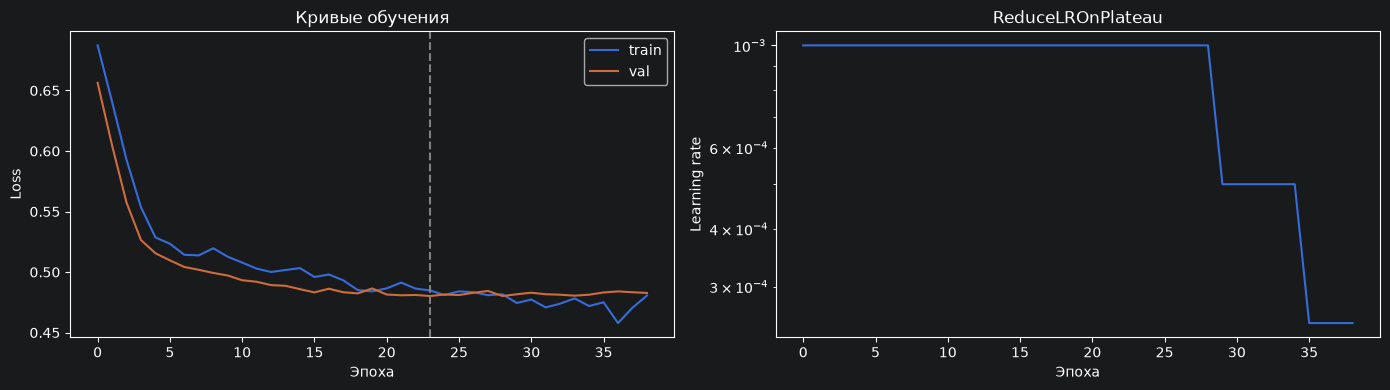

In [60]:
loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_deep.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5, min_lr=1e-6)

history = trainer_wine(model=model_deep,
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    loss_function=loss_function,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=300,
    patience=15)

best_epoch = int(np.argmin(history['val_loss'])) + 1
print('Обучение остановлено на эпохе:', len(history['val_loss']))
print('Лучшая эпоха:', best_epoch, '| val loss:', round(min(history['val_loss']), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['val_loss'], label='val')
axes[0].axvline(best_epoch - 1, color='gray', linestyle='--')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Loss')
axes[0].set_title('Кривые обучения')
axes[0].legend()
axes[1].plot(history['lr'])
axes[1].set_yscale('log')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Learning rate')
axes[1].set_title('ReduceLROnPlateau')
plt.tight_layout()
plt.show()

Accuracy: 0.7389705882352942
              precision    recall  f1-score   support

           0       0.72      0.73      0.73       128
           1       0.76      0.74      0.75       144

    accuracy                           0.74       272
   macro avg       0.74      0.74      0.74       272
weighted avg       0.74      0.74      0.74       272



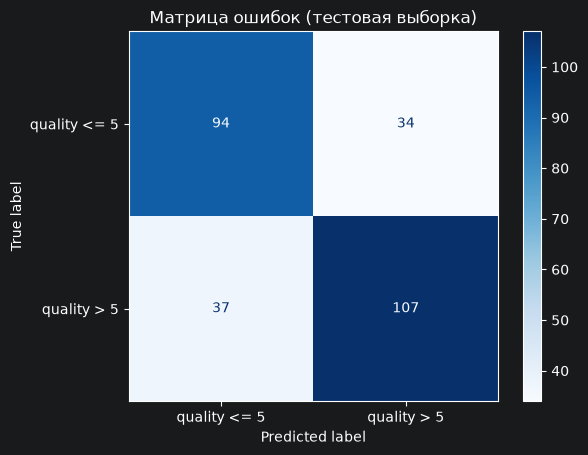

In [61]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score

_ = model_deep.eval()
acc_deep, report_deep, real_deep, pred_deep = testing_wine(model_deep, test_dataset)
print('Accuracy:', acc_deep)
print(report_deep)

ConfusionMatrixDisplay(confusion_matrix(real_deep, pred_deep),
                       display_labels=['quality <= 5', 'quality > 5']).plot(cmap='Blues')
plt.title('Матрица ошибок (тестовая выборка)')
plt.show()

In [62]:
pd.DataFrame([{
    'Модель': '2 скрытых слоя',
    'Accuracy': round(acc_deep, 4),
    'F1 (macro)': round(f1_score(real_deep, pred_deep, average='macro'), 4),
    'F1 (класс 0)': round(f1_score(real_deep, pred_deep, pos_label=0), 4),
    'F1 (класс 1)': round(f1_score(real_deep, pred_deep, pos_label=1), 4)}])

,Модель,Accuracy,F1 (macro),F1 (класс 0),F1 (класс 1)
0,2 скрытых слоя,0.739,0.7384,0.7259,0.7509


### Выводы
Сравнение с третьей работой: сопоставьте Accuracy и F1 из таблицы выше с результатами классификатора из третьей работы (результаты той работы в этом ноутбуке отсутствуют, поэтому сравнение нужно дописать по ним).